# Week 4 Improving the Essay Detector

We compare four experiments with the Week 3 soft vote. The notebook reuses the cleaned corpus, training rows, and the familiar-topic and unseen-topic tests from Week 3.

Install the pinned packages in [requirements.txt](../requirements.txt). For a GPU run, install a CUDA build of PyTorch in the notebook's Python environment. [PyTorch installation guide](https://pytorch.org/get-started/locally/)

## 1. Reuse the Week 3 splits

The dataset's `prompt_name` column defines the groups. The three held-out prompts appear only in the unseen-topic test. The two tests have identical human and AI essay counts.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import VotingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_curve
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_predict
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline

SEED = 42
# Support running the notebook from the repository root or the notebooks folder.
data_path = Path("data/train_v2_drcat_02.csv")
if not data_path.is_file():
    data_path = Path("..") / data_path

raw = pd.read_csv(data_path, usecols=["text", "label", "prompt_name"])
print("Missing values:", raw.isna().sum().to_dict())

usable = raw.dropna().copy()
# Use normalized text to find duplicates. The models use the original essays.
normalized = (
    usable["text"].str.normalize("NFKC").str.casefold()
    .str.replace(r"\s+", " ", regex=True).str.strip()
)
# keep=False marks every copy of a duplicate essay.
duplicates = normalized.duplicated(keep=False)
data = usable.loc[normalized.ne("") & ~duplicates]
assert normalized.loc[data.index].is_unique
assert set(data["label"]) == {0, 1}

print(f"Raw essays: {len(raw):,}")
print(f"Duplicate rows removed: {duplicates.sum():,}")
print(f"Clean essays: {len(data):,} across {data['prompt_name'].nunique()} topics")
display(data["label"].map({0: "Human", 1: "AI"}).value_counts().rename("Essays"))

Missing values: {'text': 0, 'label': 0, 'prompt_name': 0}
Raw essays: 44,868
Duplicate rows removed: 12
Clean essays: 44,856 across 15 topics


label
Human    27359
AI       17497
Name: Essays, dtype: int64

In [2]:
# The dataset's prompt_name column groups all essays written for the same prompt.
holdout = GroupShuffleSplit(n_splits=1, test_size=3, random_state=SEED)
remaining_rows, unseen_rows = next(holdout.split(data, groups=data["prompt_name"]))
remaining = data.iloc[remaining_rows]
unseen = data.iloc[unseen_rows]

# Match class counts so both tests have the same proportions of human and AI essays.
class_counts = unseen["label"].value_counts().sort_index()
familiar = pd.concat([
    remaining.loc[remaining["label"] == label].sample(n=count, random_state=SEED)
    for label, count in class_counts.items()
]).sort_index()
train = remaining.drop(familiar.index)

train_topics = set(train["prompt_name"])
familiar_topics = set(familiar["prompt_name"])
unseen_topics = set(unseen["prompt_name"])

# Check topic isolation and confirm that each essay belongs to a single split.
assert len(unseen_topics) == 3
assert unseen_topics.isdisjoint(train_topics | familiar_topics)
assert familiar_topics <= train_topics
assert familiar["label"].value_counts().sort_index().equals(class_counts)
all_rows = set(train.index) | set(familiar.index) | set(unseen.index)
assert len(all_rows) == len(data) == len(train) + len(familiar) + len(unseen)

tests = {"Familiar topics": familiar, "Unseen topics": unseen}
splits = {"Training": train, **tests}
counts = pd.DataFrame.from_dict({
    name: {
        "Human": int(part["label"].eq(0).sum()),
        "AI": int(part["label"].eq(1).sum()),
        "Topics": part["prompt_name"].nunique(),
    }
    for name, part in splits.items()
}, orient="index")
display(counts)
print("Unseen topics:", ", ".join(sorted(unseen_topics)))

assert len(train) == 33_674
assert len(familiar) == len(unseen) == 5_591

Unseen topics: "A Cowboy Who Rode the Waves", Grades for extracurricular activities, Phones and driving


,Human,AI,Topics
Training,19035,14639,12
Familiar topics,4162,1429,12
Unseen topics,4162,1429,3


## 2. Tune the soft-voting threshold

We keep the Week 3 model settings. Three folds grouped by topic produce a validation score for every training essay. Each score comes from a pipeline fitted on the other folds, including its TF-IDF vocabulary. We select the threshold that detects the most AI essays with at most 1% false positives on those validation predictions. The two test sets are used after this choice.

In [3]:
X_train = train["text"]
y_train = train["label"]
groups = train["prompt_name"]
grouped_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
folds = list(grouped_cv.split(X_train, y_train, groups))

for train_rows, validation_rows in folds:
    assert set(groups.iloc[train_rows]).isdisjoint(groups.iloc[validation_rows])
    assert y_train.iloc[train_rows].nunique() == y_train.iloc[validation_rows].nunique() == 2

# Both models use the same TF-IDF representation and the settings selected in Week 3.
vote = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=2, max_features=20_000)),
    ("classifier", VotingClassifier([
        ("logistic", LogisticRegression(C=4.0, solver="liblinear", max_iter=1000, random_state=SEED)),
        ("naive_bayes", ComplementNB(alpha=1.0)),
    ], voting="soft")),
])

validation_scores = cross_val_predict(
    vote, X_train, y_train, cv=folds, method="predict_proba"
)[:, 1]
fpr, recall, thresholds = roc_curve(y_train, validation_scores, drop_intermediate=False)
operating_points = pd.DataFrame({"Threshold": thresholds, "FPR": fpr, "Recall": recall})
max_validation_fpr = 0.01
selected = (
    operating_points[operating_points["FPR"] <= max_validation_fpr]
    .sort_values(["Recall", "FPR", "Threshold"], ascending=[False, True, False])
    .iloc[0]
)
vote_threshold = float(selected["Threshold"])

default_predictions = validation_scores > 0.5
default_validation = {
    "Threshold": 0.5,
    "FPR": default_predictions[y_train.to_numpy() == 0].mean(),
    "Recall": recall_score(y_train, default_predictions),
}
validation_summary = pd.DataFrame(
    [default_validation, selected.to_dict()], index=["Week 3 vote", "Tuned vote"]
)
display(validation_summary.round(4))

vote = vote.fit(X_train, y_train)

,Threshold,FPR,Recall
Week 3 vote,0.5000,0.1129,0.9535
Tuned vote,0.8303,0.0100,0.7839


## 3. Test character-level TF-IDF

We keep the logistic regression settings from Week 3. TF-IDF now uses character sequences of length three to five so the model can learn from word fragments and punctuation patterns.

In [4]:
character_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char", ngram_range=(3, 5), min_df=2, max_features=20_000
    )),
    ("classifier", LogisticRegression(
        C=4.0, solver="liblinear", max_iter=1000, random_state=SEED
    )),
])
character_model.fit(X_train, y_train)

predictions = {}
for name, test in tests.items():
    vote_scores = vote.predict_proba(test["text"])[:, 1]
    predictions[name] = {
        "Week 3 vote": vote.predict(test["text"]),
        "Tuned vote": vote_scores >= vote_threshold,
        "Character TF-IDF": character_model.predict(test["text"]),
    }

## 4. Fine-tune DistilBERT

We fine-tune the English checkpoint for one epoch on all 33,674 training essays. Each essay is tokenized to at most 256 tokens. The settings are fixed before looking at the test predictions. The model is trained locally using PyTorch and Transformers. Use a CUDA-enabled PyTorch build when running on an NVIDIA GPU.

The pretrained checkpoint is downloaded from Hugging Face on the first run, or loaded from the directory in `WEEK4_DISTILBERT_DIR`. [DistilBERT paper](https://arxiv.org/abs/1910.01108) · [Checkpoint](https://huggingface.co/distilbert/distilbert-base-uncased)

In [5]:
from os import environ

import torch
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, set_seed

checkpoint = "distilbert/distilbert-base-uncased"
revision = "12040accade4e8a0f71eabdb258fecc2e7e948be"
model_source = environ.get("WEEK4_DISTILBERT_DIR", checkpoint)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_bfloat16 = device.type == "cuda" and torch.cuda.is_bf16_supported()
max_tokens = 256
batch_size = 16
epochs = 1

tokenizer = AutoTokenizer.from_pretrained(model_source, revision=revision)
distilbert = AutoModelForSequenceClassification.from_pretrained(
    model_source, revision=revision, num_labels=2, use_safetensors=True
).to(device)

def encode_essays(texts):
    tokens = tokenizer(
        texts.tolist(), padding="max_length", truncation=True,
        max_length=max_tokens, return_tensors="pt",
    )
    return tokens["input_ids"], tokens["attention_mask"]

input_ids, attention_mask = encode_essays(X_train)
labels = torch.tensor(y_train.tolist(), dtype=torch.long)
training_batches = DataLoader(
    TensorDataset(input_ids, attention_mask, labels),
    batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(SEED),
)
optimizer = torch.optim.AdamW(distilbert.parameters(), lr=2e-5)

accelerator = torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU"
print(f"DistilBERT fine-tuning on {accelerator}, {len(labels):,} essays, {len(training_batches):,} batches", flush=True)
distilbert.train()
for epoch in range(epochs):
    total_loss = torch.zeros((), device=device)
    for step, (ids, mask, batch_labels) in enumerate(training_batches, start=1):
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_bfloat16):
            loss = distilbert(
                input_ids=ids.to(device), attention_mask=mask.to(device),
                labels=batch_labels.to(device),
            ).loss
        loss.backward()
        optimizer.step()
        total_loss += loss.detach()
        if step % 400 == 0 or step == len(training_batches):
            print(f"Epoch {epoch + 1} · batch {step}/{len(training_batches)} · mean loss {float(total_loss / step):.4f}", flush=True)

DistilBERT fine-tuning on NVIDIA GeForce RTX 4060 Laptop GPU, 33,674 essays, 2,105 batches
Epoch 1 · batch 400/2105 · mean loss 0.1268
Epoch 1 · batch 800/2105 · mean loss 0.0810
Epoch 1 · batch 1200/2105 · mean loss 0.0673
Epoch 1 · batch 1600/2105 · mean loss 0.0563
Epoch 1 · batch 2000/2105 · mean loss 0.0486
Epoch 1 · batch 2105/2105 · mean loss 0.0482


In [6]:
distilbert.eval()
for name, test in tests.items():
    batches = DataLoader(TensorDataset(*encode_essays(test["text"])), batch_size=32)
    labels = []
    with torch.inference_mode():
        for ids, mask in batches:
            with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_bfloat16):
                logits = distilbert(
                    input_ids=ids.to(device), attention_mask=mask.to(device)
                ).logits
            labels.extend(logits.argmax(dim=1).cpu().tolist())
    predictions[name]["DistilBERT"] = labels
    print(f"{name}: {len(labels):,} predictions", flush=True)

Familiar topics: 5,591 predictions
Unseen topics: 5,591 predictions


## 5. Train a small neural network from scratch

We fit word TF-IDF on the training essays with the same settings as the Week 3 logistic regression. The multilayer perceptron (MLP) has one hidden layer of 64 units. It starts with randomly initialized weights and trains for 15 passes through the training set. The model then predicts on the two held-out tests. [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)

In [7]:
from sklearn.neural_network import MLPClassifier

word_tfidf = TfidfVectorizer(min_df=2, max_features=20_000)
mlp_training_features = word_tfidf.fit_transform(X_train)
mlp = MLPClassifier(
    hidden_layer_sizes=(64,), solver="adam", batch_size=256,
    learning_rate_init=0.001, random_state=SEED,
)

epochs_mlp = 15
for epoch in range(1, epochs_mlp + 1):
    mlp.partial_fit(mlp_training_features, y_train, classes=[0, 1])
    if epoch == 1 or epoch % 5 == 0:
        print(f"Epoch {epoch}/{epochs_mlp} · Training loss {mlp.loss_:.4f}", flush=True)

for name, test in tests.items():
    test_features = word_tfidf.transform(test["text"])
    predictions[name]["Word TF-IDF + MLP"] = mlp.predict(test_features)

Epoch 1/15 · Training loss 0.2717
Epoch 5/15 · Training loss 0.0112
Epoch 10/15 · Training loss 0.0038
Epoch 15/15 · Training loss 0.0022


## 6. Compare both held-out tests

Precision is the share of flagged essays that are actually AI-generated. Recall is the share of AI essays detected. The human false-positive rate is the share of human essays flagged as AI. Each row reports the same test essays for that model.

,Test,Model,Accuracy,Precision (AI),Recall (AI),F1 (AI),Human false positives (%),False alerts,Missed AI essays
0,Familiar topics,Week 3 vote,0.988,0.982,0.973,0.977,0.625,26,39
1,Familiar topics,Tuned vote,0.975,1.000,0.901,0.948,0.000,0,142
2,Familiar topics,Character TF-IDF,0.996,0.996,0.987,0.992,0.120,5,18
3,Familiar topics,DistilBERT,0.986,0.953,0.994,0.973,1.682,70,8
4,Familiar topics,Word TF-IDF + MLP,0.996,0.994,0.990,0.992,0.192,8,14
5,Unseen topics,Week 3 vote,0.954,0.979,0.838,0.903,0.625,26,232
6,Unseen topics,Tuned vote,0.901,0.998,0.613,0.759,0.048,2,553
7,Unseen topics,Character TF-IDF,0.950,0.906,0.899,0.902,3.220,134,144
8,Unseen topics,DistilBERT,0.963,0.876,0.996,0.932,4.829,201,6
9,Unseen topics,Word TF-IDF + MLP,0.954,0.947,0.868,0.905,1.682,70,189


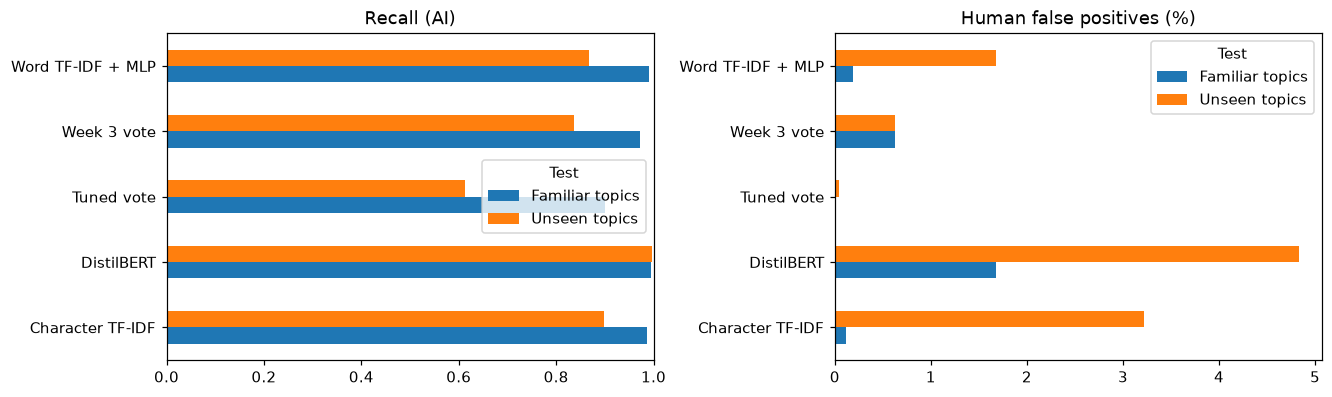

In [8]:
rows = []
for test_name, test in tests.items():
    truth = test["label"]
    for model_name, predicted in predictions[test_name].items():
        tn, fp, fn, tp = confusion_matrix(truth, predicted, labels=[0, 1]).ravel()
        rows.append({
            "Test": test_name,
            "Model": model_name,
            "Accuracy": accuracy_score(truth, predicted),
            "Precision (AI)": precision_score(truth, predicted, zero_division=0),
            "Recall (AI)": recall_score(truth, predicted),
            "F1 (AI)": f1_score(truth, predicted, zero_division=0),
            "Human false positives (%)": 100 * fp / (tn + fp),
            "False alerts": int(fp),
            "Missed AI essays": int(fn),
        })

results = pd.DataFrame(rows)
display(results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
for ax, metric in zip(axes, ["Recall (AI)", "Human false positives (%)"]):
    results.pivot(index="Model", columns="Test", values=metric).plot.barh(
        ax=ax, title=metric, ylabel=""
    )
axes[0].set_xlim(0, 1)
plt.show()

## Results on unseen topics

The Week 3 vote detected 1,197 AI essays and produced 26 false alerts. The tuned threshold (0.8303) cut the number of false alerts to 2. It detected 876 AI essays and reduced AI-class F1 from 0.903 to 0.759.

Character TF-IDF improved recall compared with the Week 3 word-based logistic regression (89.9% versus 88.5%). False alerts increased from 129 to 134.

DistilBERT detected 1,423 of the 1,429 AI essays and produced 201 false alerts. DistilBERT delivered the highest AI-class F1 (0.932). 

The word TF-IDF MLP achieved an AI-class F1 of 0.905 on unseen topics. It detected 1,240 of 1,429 AI essays and produced 70 false alerts. With the same word TF-IDF settings, the Week 3 logistic regression achieved an F1 of 0.896 and produced 129 false alerts.

The threshold was chosen using grouped validation. The Week 3 test sets make the experiments directly comparable. A fresh set of writing prompts could provide an independent confirmation. The DistilBERT run used one training epoch and at most 256 tokens per essay, including special tokens.